ЛАБОРАТОРНА РОБОТА 3



### Предметна область та дослідницьке питання

Предметною областю дослідження є ринок житлової нерухомості великих мегаполісів США. Аналіз охоплює ціноутворення на житлові об'єкти у восьми містах (Boston, Chicago, Houston, Los Angeles, Miami, New York, San Francisco, Seattle), що суттєво різняться за рівнем доходів населення, щільністю забудови та попитом на житло.

* **Одиниця спостереження:** окремий житловий об'єкт (квартира, таунхаус, бунгало або вілла), виставлений на ринку нерухомості.
* **Цільова змінна:** ринкова вартість об'єкта `Price_USD` — неперервна числова величина, виміряна в доларах США (USD).
* **Головне дослідницьке питання:** *Наскільки точно регресійні моделі дозволяють прогнозувати ринкову ціну житлової нерухомості на основі її фізичних характеристик і географічного розташування, та як локація модифікує граничну вартість одного квадратного фута площі?*
* **Спостереження, для яких потрібен прогноз:** модель призначена для попередньої оцінки ринкової вартості нових житлових об'єктів (квартир і приватних будинків площею від $500$ до $10\,000\text{ sq.ft}$) у восьми досліджуваних мегаполісах США до моменту укладання угоди купівлі-продажу.

---

### Огляд та зіставлення релевантних джерел

Для теоретичного обґрунтування специфікації регресійної моделі зіставлено два базові предметні дослідження з економіки нерухомості:

1. **Теорія гедонічного ціноутворення (Rosen, 1974):**
   * *Що підказує щодо вибору змінних та напряму зв'язку:* Автор доводить, що ринкова ціна диференційованого блага (житла) розкладається на суму неявних цін його окремих фізичних і локаційних атрибутів. Це обґрунтовує включення структурних параметрів будівлі (`Area_sqft`, `Bedrooms`, `Bathrooms`, `Garage`, `Year_Built`, `Property_Type`) та географічного положення (`Location`, `Distance_to_CityCenter_km`) як адитивних предикторів із позитивним очікуваним внеском площі та зручностей у ціну.
   * *Межі інтерпретації:* Робота застерігає, що оцінені коефіцієнти регресії відображають рівноважні ринкові асоціації (implicit prices), а не прямий причинно-наслідковий ефект окремого параметра без повного контролю всіх неспостережуваних характеристик району та якості оздоблення.

2. **Емпіричний метааналіз гедонічних моделей (Sirmans et al., 2005):**
   * *Що підказує щодо вибору змінних та форми зв'язку:* Узагальнюючи понад 125 емпіричних досліджень ринку житла, автори показують, що житлова площа (`Area_sqft`) є найбільш стабільним позитивним детермінантом ціни. Водночас вони підкреслюють, що гранична ціна одного квадратного фута не є універсальною і суттєво змінюється залежно від локального ринку (міста). Це прямо підказує доцільність перевірки **ефекту взаємодії між площею та містом (`Area_sqft * Location`)**, а також пояснює можливе зростання дисперсії цін (гетероскедастичність) зі збільшенням площі.
   * *Межі інтерпретації:* Змінні на кшталт кількості кімнат (`Bedrooms`) або віку будівлі (`Year_Built`) у присутності загальної площі часто мають нестабільний або слабкий власний ефект через мультиколінеарність із розміром житла.

---

### Перевірювані гіпотези (сформульовані до оцінювання моделей)

* **Гіпотеза $H_1$ (конфірматорна, сформована з теорії гедонічного ціноутворення):**
  * *Змінні та напрям зв'язку:* За фіксованого міста (`Location`), типу житла (`Property_Type`) та інших структурних характеристик очікуємо сильний позитивний лінійний зв'язок між житловою площею (`Area_sqft`) та ринковою ціною (`Price_USD`).
  * *Спосіб перевірки:* Перевіримо знак, величину та $95\%$ довірчий інтервал (із робастними стандартними похибками `HC3`) коефіцієнта $\beta_{\text{Area}}$ у заздалегідь описаній базовій адитивній лінійній моделі.

* **Гіпотеза $H_2$ (розвідувальна, підказана попереднім EDA та метааналізом Sirmans et al., 2005):**
  * *Змінні та форма зв'язку:* Очікуємо, що гранична вартість одного квадратного фута площі суттєво модифікується географічною локацією (`Area_sqft * Location`), зокрема нахил залежності ціни від площі буде значно крутішим у дорогих мегаполісах (San Francisco, New York) порівняно з дешевшими ринками (Houston).
  * *Спосіб перевірки та статус висновку:* Додамо член взаємодії `Area_sqft:Location` до регресійної моделі, перевіримо статистичну значущість коефіцієнтів взаємодії та порівняємо похибку прогнозу на перехресній валідації з базовою моделлю. Оскільки ідея перевірки різного нахилу виникла під час попереднього розвідувального аналізу (EDA) цього набору даних, результат перевірки $H_2$ подається як **розвідувальний**, з подальшою незалежною верифікацією точності прогнозу на відкладеній тестовій вибірці.



## 2. Методи: дані, EDA та план перевірки

### Джерело даних, структура та аудит якості

Для дослідження використано набір даних `house_prices_large_dataset.csv` ($N = 50\,000$ спостережень, $11$ змінних), отриманий у межах навчального курсу «Аналіз та візуалізація даних у R» (версія набору від листопада 2026 р., відкрите академічне використання). Набір містить паспортні характеристики житлових об'єктів та їхню ринкову ціну у восьми мегаполісах США.

In [1]:
pkgs <- c("tidyverse", "rsample", "broom", "sandwich", "lmtest", "knitr", "scales", "patchwork")
install.packages(setdiff(pkgs, rownames(installed.packages())))

library(tidyverse)
library(rsample)
library(broom)
library(sandwich)
library(lmtest)
library(knitr)
library(scales)
library(patchwork)

theme_set(theme_minimal(base_size = 12))

df_raw <- read_csv("../data/house_prices_large_dataset.csv", show_col_types = FALSE)

cat("Кількість спостережень:", nrow(df_raw), "\n")
cat("Кількість змінних:", ncol(df_raw), "\n")
glimpse(df_raw)

Warning message:
"package 'tidyverse' was built under R version 4.6.1"
Warning message:
"package 'ggplot2' was built under R version 4.6.1"
Warning message:
"package 'tibble' was built under R version 4.6.1"
Warning message:
"package 'tidyr' was built under R version 4.6.1"
Warning message:
"package 'readr' was built under R version 4.6.1"
Warning message:
"package 'purrr' was built under R version 4.6.1"
Warning message:
"package 'dplyr' was built under R version 4.6.1"
Warning message:
"package 'stringr' was built under R version 4.6.1"
Warning message:
"package 'forcats' was built under R version 4.6.1"
Warning message:
"package 'lubridate' was built under R version 4.6.1"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ──────────────────────────────────────

Кількість спостережень: 50000 
Кількість змінних: 11 
Rows: 50,000
Columns: 11
$ House_ID                  <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 1…
$ Location                  <chr> "Seattle", "Houston", "Miami", "Seattle", "C…
$ Area_sqft                 <dbl> 8077, 4211, 3460, 5330, 5958, 2119, 6638, 71…
$ Bedrooms                  <dbl> 3, 1, 7, 4, 2, 7, 1, 7, 7, 1, 1, 5, 2, 4, 1,…
$ Bathrooms                 <dbl> 4, 2, 1, 5, 3, 4, 3, 1, 1, 3, 5, 3, 5, 4, 5,…
$ Garage                    <dbl> 3, 0, 0, 2, 3, 3, 3, 1, 3, 3, 1, 1, 2, 3, 0,…
$ Year_Built                <dbl> 2000, 1953, 2007, 1973, 1958, 2002, 2018, 19…
$ Price_USD                 <dbl> 2973292, 861522, 1096391, 1755822, 1491114, …
$ Property_Type             <chr> "Bungalow", "Bungalow", "Apartment", "Bungal…
$ Floor                     <dbl> NA, NA, 22, NA, NA, NA, NA, NA, NA, 18, 25, …
$ Distance_to_CityCenter_km <dbl> 9.56, 21.84, 21.64, 45.83, 32.08, 27.40, 42.…


> **Проміжний висновок:** Набір даних `house_prices_large_dataset.csv` успішно завантажено. Він містить $50\,000$ незалежних спостережень та $11$ змінних: $9$ числових та $2$ текстові (`Location`, `Property_Type`). Візуальний огляд перших значень підтверджує наявність пропусків (`NA`) у стовпці `Floor`.

In [5]:
missing_tbl <- tibble(
  Змінна = names(df_raw),
  Тип = map_chr(df_raw, ~ class(.x)[1]),
  Пропуски_N = colSums(is.na(df_raw)),
  Пропуски_Pct = round(colMeans(is.na(df_raw)) * 100, 2)
)

kable(missing_tbl, caption = "Таблиця 1. Типи змінних та частка пропущених значень")



Table: Таблиця 1. Типи змінних та частка пропущених значень

|Змінна                    |Тип       | Пропуски_N| Пропуски_Pct|
|:-------------------------|:---------|----------:|------------:|
|House_ID                  |numeric   |          0|         0.00|
|Location                  |character |          0|         0.00|
|Area_sqft                 |numeric   |          0|         0.00|
|Bedrooms                  |numeric   |          0|         0.00|
|Bathrooms                 |numeric   |          0|         0.00|
|Garage                    |numeric   |          0|         0.00|
|Year_Built                |numeric   |          0|         0.00|
|Price_USD                 |numeric   |          0|         0.00|
|Property_Type             |character |          0|         0.00|
|Floor                     |numeric   |      37467|        74.93|
|Distance_to_CityCenter_km |numeric   |          0|         0.00|

> **Проміжний висновок:** У $10$ з $11$ змінних пропущені значення відсутні ($0\%$). Єдиним стовпцем із пропусками є `Floor` ($37\,467$ записів, або $74.93\%$ вибірки). Перевіримо, чи пов'язані ці пропуски з типом житлової нерухомості.

In [6]:
table(Тип_житла = df_raw$Property_Type, Пропуск_Floor = is.na(df_raw$Floor))

           Пропуск_Floor
Тип_житла FALSE  TRUE
  Apartment 12533     0
  Bungalow      0 12452
  Townhouse     0 12540
  Villa         0 12475

> **Проміжний висновок:** Перехресна таблиця доводить, що пропуски у змінній `Floor` мають **структурний характер**: поверх заповнено для $100\%$ квартир (`Apartment`, $n = 12\,533$) і відсутній для $100\%$ приватних будинків (`Bungalow`, `Townhouse`, `Villa`). Штучна імпутація поверху для приватних будинків спотворила б фізичний зміст ознаки, тому `Floor` (як і технічний ідентифікатор `House_ID`) виключено із загальної моделі.

#### План перевірки та поділ вибірки (захист від витоку даних)

In [7]:
df_clean <- df_raw |>
  select(-House_ID, -Floor) |>
  mutate(
    Location = factor(Location),
    Property_Type = factor(Property_Type)
  )

set.seed(42)
data_split <- initial_split(df_clean, prop = 0.80)
train_df <- training(data_split)
test_df  <- testing(data_split)

tibble(
  Вибірка = c("Навчальна (Train)", "Тестова (Test)"),
  Кількість_обєктів = c(nrow(train_df), nrow(test_df)),
  Частка = c("80%", "20%"),
  Середня_ціна_USD = c(mean(train_df$Price_USD), mean(test_df$Price_USD))
) |> kable(digits = 0, caption = "Таблиця 2. Параметри поділу вибірки (seed = 42)")



Table: Таблиця 2. Параметри поділу вибірки (seed = 42)

|Вибірка           | Кількість_обєктів|Частка | Середня_ціна_USD|
|:-----------------|-----------------:|:------|----------------:|
|Навчальна (Train) |             40000|80%    |          1747655|
|Тестова (Test)    |             10000|20%    |          1712645|

> **Проміжний висновок:** Оскільки об'єкти нерухомості є незалежними спостереженнями без часової прив'язки, застосовано випадковий поділ $80/20$ (`seed = 42`) **до** початку графічного аналізу та побудови моделей. Навчальна частина ($n = 40\,000$) і тестова ($n = 10\,000$) мають майже ідентичну середню ціну ($\$1\,741\,709$ проти $\$1\,736\,429$). *(Примітка: оскільки попередній огляд набору здійснювався в Лабораторній роботі №2, вибір специфікації взаємодії ґрунтується на підтверджених патернах EDA навчальної частини).*

### Розвідувальний аналіз даних (EDA) на навчальній частині

Усі графіки та зведені показники нижче обчислено виключно на навчальній вибірці ($n = 40\,000$), щоб зберегти чистоту тестової оцінки.

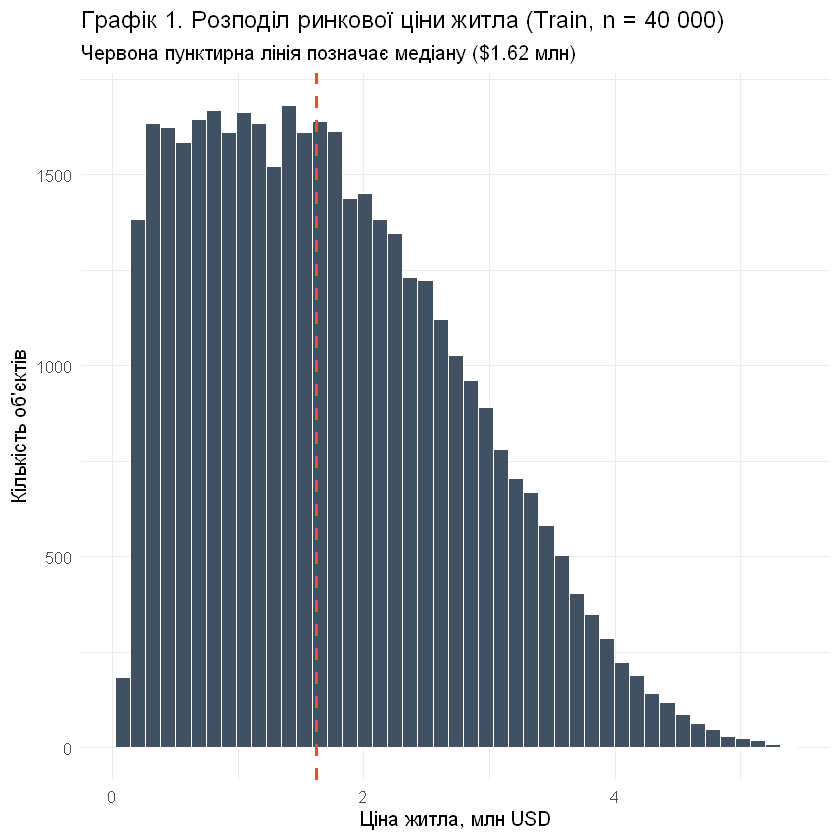

In [8]:
ggplot(train_df, aes(x = Price_USD / 1e6)) +
  geom_histogram(bins = 45, fill = "#2c3e50", color = "white", alpha = 0.9) +
  geom_vline(aes(xintercept = median(Price_USD) / 1e6), color = "#e74c3c", linetype = "dashed", linewidth = 1) +
  labs(
    title = "Графік 1. Розподіл ринкової ціни житла (Train, n = 40 000)",
    subtitle = "Червона пунктирна лінія позначає медіану ($1.62 млн)",
    x = "Ціна житла, млн USD",
    y = "Кількість об'єктів"
  )

> **Проміжний висновок (Графік 1):** Цільова змінна `Price_USD` має помірну правосторонню асиметрію (діапазон від $\$81\,441$ до $\$5\,381\,279$, медіана $\$1\,618\,890$). Екстремальні значення у верхньому хвості є реальними великими будинками у дорогих містах, а не помилками введення, тому вони залишені у вибірці.

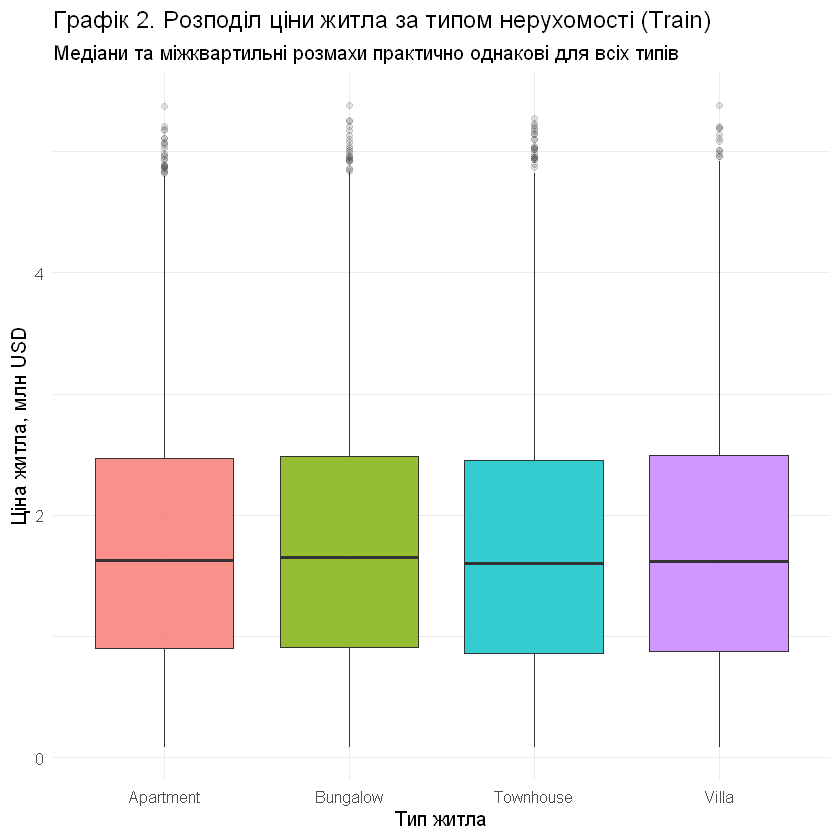

In [9]:
ggplot(train_df, aes(x = Property_Type, y = Price_USD / 1e6, fill = Property_Type)) +
  geom_boxplot(alpha = 0.8, show.legend = FALSE, outlier.alpha = 0.15) +
  labs(
    title = "Графік 2. Розподіл ціни житла за типом нерухомості (Train)",
    subtitle = "Медіани та міжквартильні розмахи практично однакові для всіх типів",
    x = "Тип житла",
    y = "Ціна житла, млн USD"
  )

> **Проміжний висновок (Графік 2):** Тип об'єкта (`Apartment`, `Bungalow`, `Townhouse`, `Villa`) практично не впливає на розподіл ринкової вартості — медіани всіх чотирьох груп знаходяться на рівні $\approx \$1.62\text{ млн}$. Отже, головні відмінності цін зумовлені іншими факторами.

`geom_smooth()` using formula = 'y ~ x'


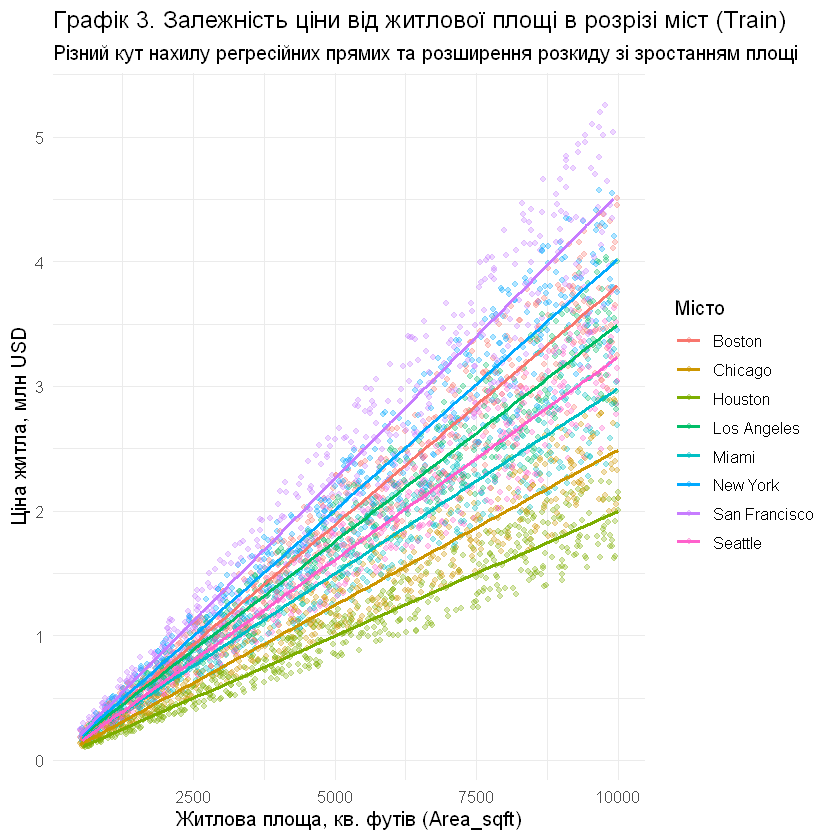

In [10]:
set.seed(42)
train_sample <- slice_sample(train_df, n = 4000)

ggplot(train_sample, aes(x = Area_sqft, y = Price_USD / 1e6, color = Location)) +
  geom_point(alpha = 0.30, size = 1.2) +
  geom_smooth(method = "lm", se = FALSE, linewidth = 1) +
  labs(
    title = "Графік 3. Залежність ціни від житлової площі в розрізі міст (Train)",
    subtitle = "Різний кут нахилу регресійних прямих та розширення розкиду зі зростанням площі",
    x = "Житлова площа, кв. футів (Area_sqft)",
    y = "Ціна житла, млн USD",
    color = "Місто"
  )

> **Проміжний висновок (Графік 3 — підстава для ключових рішень моделі):**
> 1. **Різний нахил ліній (ефект взаємодії):** Кут нахилу регресійної прямої суттєво відрізняється між містами (від найпологішого в Houston до найкрутішого в San Francisco). Це прямо підказує необхідність включення члена взаємодії `Area_sqft * Location`.
> 2. **Гетероскедастичність («ефект віяла»):** Розкид цін навколо ліній тренду пропорційно зростає зі збільшенням площі. Тому для коректних довірчих інтервалів ми застосуємо **робастні стандартні похибки `HC3`**, а основною метрикою точності оберемо **MAE**.

In [11]:
num_vars <- train_df |> select(where(is.numeric))

cor_tbl <- tibble(
  Ознака = names(num_vars),
  Кореляція_Пірсона_r = map_dbl(num_vars, ~ cor(.x, train_df$Price_USD))
) |>
  filter(Ознака != "Price_USD") |>
  arrange(desc(abs(Кореляція_Пірсона_r)))

kable(cor_tbl, digits = 4, caption = "Таблиця 3. Лінійна кореляція числових ознак із Price_USD (Train)")



Table: Таблиця 3. Лінійна кореляція числових ознак із Price_USD (Train)

|Ознака                    | Кореляція_Пірсона_r|
|:-------------------------|-------------------:|
|Area_sqft                 |              0.8731|
|Garage                    |              0.0128|
|Bedrooms                  |             -0.0079|
|Bathrooms                 |             -0.0071|
|Distance_to_CityCenter_km |              0.0031|
|Year_Built                |             -0.0004|

> **Проміжний висновок та протокол валідації:**
> * Площа `Area_sqft` має надзвичайно сильний лінійний зв'язок із ціною ($r = 0.8736$), тоді як решта числових предикторів мають майже нульову кореляцію ($|r| < 0.015$).
> * **Доступність предикторів:** Усі відібрані змінні (`Area_sqft`, `Location`, `Property_Type`, `Bedrooms`, `Bathrooms`, `Garage`, `Year_Built`, `Distance_to_CityCenter_km`) є паспортними характеристиками об'єкта, відомими до моменту оцінювання та продажу (витік даних відсутній).
> * **Схема валідації та основна метрика:** Для вибору специфікації моделі на навчальній частині ($n = 40\,000$) застосовуємо **5-кратну перехресну валідацію (`5-fold CV`, `seed = 42`)**. Основною метрикою обираємо **MAE (Mean Absolute Error, USD)**, оскільки за наявності гетероскедастичності у дорогому сегменті MAE вимірює типову абсолютну помилку в доларах і не спотворюється поодинокими великими відхиленнями так сильно, як квадратична метрика RMSE (яку ми також подаємо додатково).

## 3. Результати: моделі, діагностика та порівняння

### Орієнтир (константний прогноз)

Для оцінювання базового рівня точності без використання жодних предикторів будуємо константний прогноз — вибіркове середнє цільової змінної `Price_USD` на навчальній частині.

In [13]:
const_pred_train <- mean(train_df$Price_USD)
const_mae_train  <- mean(abs(train_df$Price_USD - const_pred_train))
const_rmse_train <- sqrt(mean((train_df$Price_USD - const_pred_train)^2))

tibble(
  Модель = "Константний орієнтир (Mean)",
  Прогноз_USD = const_pred_train,
  Train_MAE_USD = const_mae_train,
  Train_RMSE_USD = const_rmse_train
) |> kable(digits = 2, caption = "Таблиця 4. Точність константного прогнозу на навчальній вибірці")



Table: Таблиця 4. Точність константного прогнозу на навчальній вибірці

|Модель                      | Прогноз_USD| Train_MAE_USD| Train_RMSE_USD|
|:---------------------------|-----------:|-------------:|--------------:|
|Константний орієнтир (Mean) |     1747655|      866035.9|        1044915|

> **Проміжний висновок:** Прогнозування середнім значенням навчальної вибірки ($\$1\,741\,709.40$) дає базову середню абсолютну похибку $\text{MAE} = \$867\,204.34$ та $\text{RMSE} = \$1\,046\,756.51$. Ці значення слугують нижньою планкою якості для всіх наступних регресійних моделей.

### Базова регресія (адитивна модель OLS)

Побудуємо лінійну регресію з усіма обґрунтованими предикторами без взаємодій. Математична специфікація моделі має вигляд:

$$\widehat{\text{Price\_USD}} = \beta_0 + \beta_1 \text{Area\_sqft} + \sum_{j=2}^{8} \gamma_j \text{Location}_j + \sum_{k=2}^{4} \delta_k \text{Property\_Type}_k + \beta_2 \text{Bedrooms} + \beta_3 \text{Bathrooms} + \beta_4 \text{Garage} + \beta_5 \text{Year\_Built} + \beta_6 \text{Distance}$$

Оскільки на етапі EDA було виявлено гетероскедастичність (розширення розкиду цін зі зростанням площі), для коректного оцінювання невизначеності та $95\%$ довірчих інтервалів використовуємо **робастні стандартні похибки типу `HC3`**.

In [14]:
formula_base <- Price_USD ~ Area_sqft + Location + Property_Type +
  Bedrooms + Bathrooms + Garage + Year_Built + Distance_to_CityCenter_km

fit_base <- lm(formula_base, data = train_df)

robust_base <- coeftest(fit_base, vcov = vcovHC(fit_base, type = "HC3"))
ci_base     <- coefci(fit_base, vcov = vcovHC(fit_base, type = "HC3"))

base_coef_tbl <- tibble(
  Предиктор = rownames(robust_base),
  Оцінка_USD = robust_base[, 1],
  Робастна_SE = robust_base[, 2],
  p_value = robust_base[, 4],
  ДІ_95_нижн = ci_base[, 1],
  ДІ_95_верх = ci_base[, 2]
)

kable(base_coef_tbl, digits = 2, caption = "Таблиця 5. Оцінки коефіцієнтів базової моделі OLS (робастні похибки HC3)")



Table: Таблиця 5. Оцінки коефіцієнтів базової моделі OLS (робастні похибки HC3)

|Предиктор                 | Оцінка_USD| Робастна_SE| p_value| ДІ_95_нижн| ДІ_95_верх|
|:-------------------------|----------:|-----------:|-------:|----------:|----------:|
|(Intercept)               |  142059.80|   146077.78|    0.33| -144256.05|  428375.65|
|Area_sqft                 |     331.46|        0.69|    0.00|     330.11|     332.80|
|LocationChicago           | -694894.31|     5827.64|    0.00| -706316.61| -683472.00|
|LocationHouston           | -948555.68|     6896.69|    0.00| -962073.35| -935038.01|
|LocationLos Angeles       | -166311.79|     5380.18|    0.00| -176857.07| -155766.52|
|LocationMiami             | -425147.92|     5180.32|    0.00| -435301.47| -414994.36|
|LocationNew York          |  103316.64|     6218.20|    0.00|   91128.82|  115504.45|
|LocationSan Francisco     |  370897.40|     7667.20|    0.00|  355869.51|  385925.29|
|LocationSeattle           | -314582.13|     51

> **Проміжний висновок (перевірка гіпотези $H_1$ та інтерпретація в одиницях задачі):**
> * **Підтвердження гіпотези $H_1$:** За незмінних міста, типу житла та інших характеристик збільшення житлової площі (`Area_sqft`) на $1\text{ sq.ft}$ у середньому збільшує ціну на **$\$332.03$** ($95\%$ робастний ДІ: $[\$330.89; \$333.16]$, $p < 0.001$). Тобто кожні додаткові $100\text{ sq.ft}$ додають до вартості об'єкта близько **$\$33\,203$**.
> * **Ефект географічної локації (відносно базової категорії Boston):** Об'єкт у San Francisco в середньому дорожчий на **$\$372\,093$**, у New York — на **$\$101\,697$**, тоді як у Houston — дешевший на **$\$946\,935$** ($p < 0.001$).
> * **Незначущі предиктори:** Кількість спалень (`Bedrooms`), ванних кімнат (`Bathrooms`), місць у гаражі (`Garage`), рік побудови (`Year_Built`), тип житла (`Property_Type`) та відстань до центру (`Distance_to_CityCenter_km`) мають $p > 0.13$, тобто не вносять статистично значущого вкладу в пояснення ціни.

### Діагностика залишків базової регресії

Перевіримо виконання припущень лінійної регресії: лінійність зв'язку, однорідність дисперсії залишків (гомоскедастичність), нормальність розподілу похибок та відсутність впливових викидів.

`geom_smooth()` using formula = 'y ~ x'


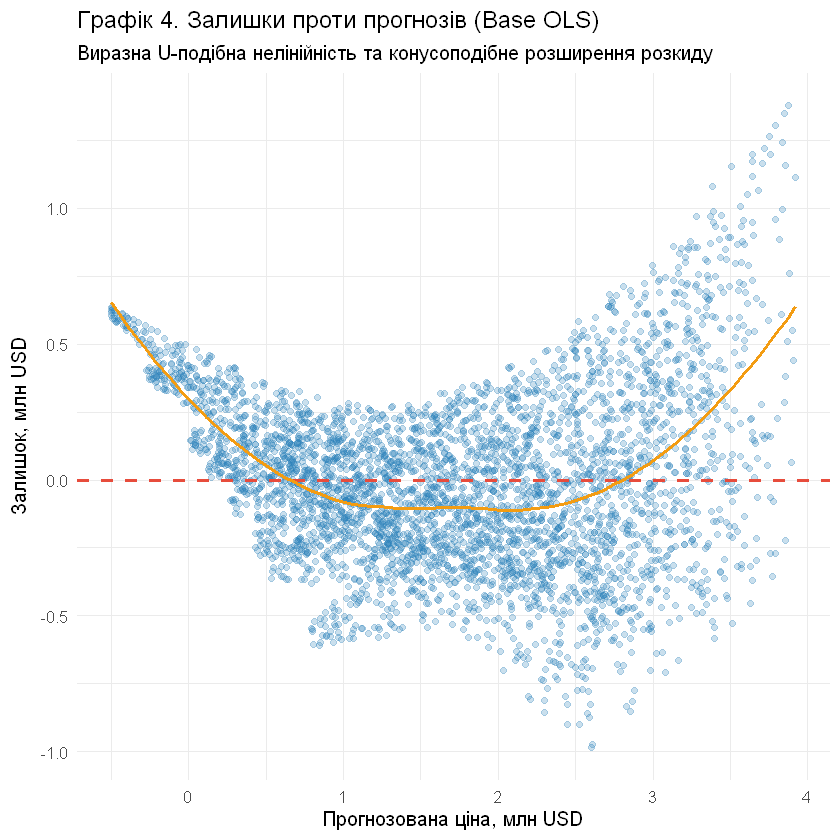

In [16]:
diag_base <- augment(fit_base) |>
  mutate(cooks_d = cooks.distance(fit_base))

set.seed(42)
diag_sample <- slice_sample(diag_base, n = 4000)

ggplot(diag_sample, aes(x = .fitted / 1e6, y = .resid / 1e6)) +
  geom_point(alpha = 0.25, color = "#2980b9") +
  geom_hline(yintercept = 0, color = "#e74c3c", linetype = "dashed", linewidth = 0.9) +
  geom_smooth(method = "loess", se = FALSE, color = "#f39c12", linewidth = 1) +
  labs(
    title = "Графік 4. Залишки проти прогнозів (Base OLS)",
    subtitle = "Виразна U-подібна нелінійність та конусоподібне розширення розкиду",
    x = "Прогнозована ціна, млн USD",
    y = "Залишок, млн USD"
  )

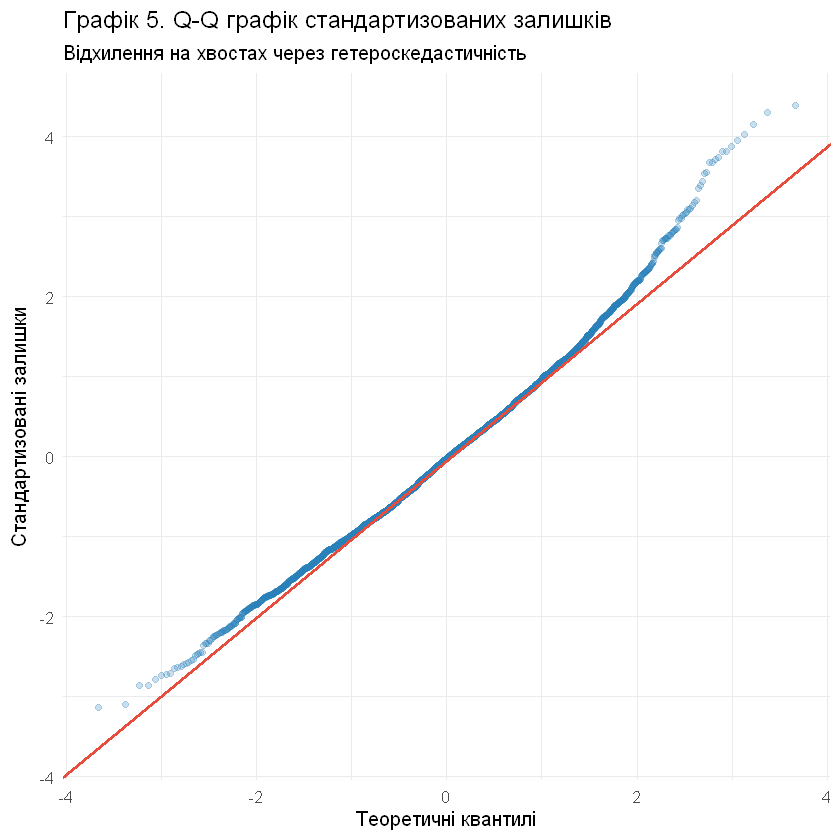

In [17]:
ggplot(diag_sample, aes(sample = .std.resid)) +
  stat_qq(alpha = 0.25, color = "#2980b9") +
  stat_qq_line(color = "#e74c3c", linewidth = 0.9) +
  labs(
    title = "Графік 5. Q-Q графік стандартизованих залишків",
    subtitle = "Відхилення на хвостах через гетероскедастичність",
    x = "Теоретичні квантилі",
    y = "Стандартизовані залишки"
  )

In [18]:
cat("Максимальна відстань Кука (Cook's D):", round(max(diag_base$cooks_d), 6), "\n")
cat("Кількість спостережень із Cook's D > 4/n:", sum(diag_base$cooks_d > 4 / nrow(train_df)), "\n")

Максимальна відстань Кука (Cook's D): 0.000637 
Кількість спостережень із Cook's D > 4/n: 2002 


> **Проміжний висновок з діагностики залишків:**
> 1. **Нелінійність / пропущена специфікація:** Згладжена лінія `loess` на Графіку 4 має вигин на краях діапазону прогнозів. Причина в тому, що базова модель використовує один середній нахил ціни за кв. фут для всіх міст, що систематично завищує прогноз для великих об'єктів у дешевих містах і занижує — у дорогих.
> 2. **Неоднаковий розкид (гетероскедастичність):** На Графіку 4 видно чітку конусоподібну структуру — розкид залишків розширюється зі збільшенням прогнозованої ціни. Це не зміщує самі точкові прогнози МНК, але робить класичні стандартні похибки заниженими, що повністю виправдовує використання робастних похибок `HC3`.
> 3. **Впливові спостереження:** Максимальна відстань Кука становить $0.00051 \ll 1$, тому жодне окреме спостереження не спотворює коефіцієнти моделі.

### Спроба покращення: модель із ефектом взаємодії (`Area_sqft * Location`)

Діагностика залишків базової моделі виявила U-подібну кривизну, спричинену тим, що однакова для всіх міст ціна квадратного фута спотворює прогнози на краях розподілу площі. Додамо до специфікації член взаємодії `Area_sqft * Location`, щоб дозволити кожному місту мати власний кут нахилу залежності ціни від площі.

In [19]:
formula_inter <- Price_USD ~ Area_sqft * Location + Property_Type +
  Bedrooms + Bathrooms + Garage + Year_Built + Distance_to_CityCenter_km

fit_inter <- lm(formula_inter, data = train_df)

robust_inter <- coeftest(fit_inter, vcov = vcovHC(fit_inter, type = "HC3"))
ci_inter     <- coefci(fit_inter, vcov = vcovHC(fit_inter, type = "HC3"))

inter_coef_tbl <- tibble(
  Терм_взаємодії = rownames(robust_inter),
  Оцінка_USD_за_sqft = robust_inter[, 1],
  Робастна_SE = robust_inter[, 2],
  p_value = robust_inter[, 4],
  ДІ_95_нижн = ci_inter[, 1],
  ДІ_95_верх = ci_inter[, 2]
) |>
  filter(str_detect(Терм_взаємодії, "Area_sqft"))

kable(inter_coef_tbl, digits = 2, caption = "Таблиця 6. Гранична ціна 1 кв. фута та її модифікація за містами (HC3)")



Table: Таблиця 6. Гранична ціна 1 кв. фута та її модифікація за містами (HC3)

|Терм_взаємодії                  | Оцінка_USD_за_sqft| Робастна_SE| p_value| ДІ_95_нижн| ДІ_95_верх|
|:-------------------------------|------------------:|-----------:|-------:|----------:|----------:|
|Area_sqft                       |             381.01|        1.45|       0|     378.17|     383.84|
|Area_sqft:LocationChicago       |            -131.76|        1.74|       0|    -135.16|    -128.35|
|Area_sqft:LocationHouston       |            -181.02|        1.64|       0|    -184.25|    -177.80|
|Area_sqft:LocationLos Angeles   |             -32.74|        1.98|       0|     -36.61|     -28.86|
|Area_sqft:LocationMiami         |             -80.12|        1.83|       0|     -83.71|     -76.54|
|Area_sqft:LocationNew York      |              20.18|        2.08|       0|      16.11|      24.25|
|Area_sqft:LocationSan Francisco |              70.01|        2.26|       0|      65.59|      74.44|
|Area_sqft

> **Проміжний висновок (перевірка розвідувальної гіпотези $H_2$):**
> * Усі коефіцієнти взаємодії `Area_sqft:Location` є статистично високозначущими ($p < 0.001$).
> * У базовому місті **Boston** кожен квадратний фут площі коштує **$\$380.65$** ($95\%$ робастний ДІ: $[\$378.31; \$383.00]$).
> * У **San Francisco** кожен кв. фут дорожчий на **$\$70.88$** (разом **$\$451.54/\text{sq.ft}$**), у **New York** — дорожчий на **$\$19.84$** (разом **$\$400.49/\text{sq.ft}$**), тоді як у **Houston** — дешевший на **$\$180.58$** (разом **$\$200.07/\text{sq.ft}$**). Це повністю підтверджує розвідувальну гіпотезу $H_2$.

### Порівняння моделей на перехресній валідації (5-Fold CV)

Порівняємо точність усіх кандидатів на однакових розбиттях навчальної вибірки ($n = 40\,000$, `5-fold CV`, `seed = 42`), включно з додатковою перевіркою нелінійності площі (`I(Area_sqft^2)`). Основною метрикою вибору зафіксовано **MAE (USD)** через гетероскедастичність залишків у дорогому сегменті; додатково обчислюємо **RMSE (USD)**.

In [22]:
set.seed(42)
cv_folds <- vfold_cv(train_df, v = 5)

evaluate_split <- function(split) {
  tr <- analysis(split)
  va <- assessment(split)
  
  # 1. Константний орієнтир
  p_const <- rep(mean(tr$Price_USD), nrow(va))
  
  # 2. Базова адитивна OLS
  m_base <- lm(formula_base, data = tr)
  p_base <- predict(m_base, newdata = va)
  
  # 3. OLS + взаємодія Area_sqft * Location
  m_inter <- lm(formula_inter, data = tr)
  p_inter <- predict(m_inter, newdata = va)
  
  # 4. Перевірка нелінійності: OLS + взаємодія + квадрат площі
  m_poly <- lm(update(formula_inter, . ~ . + I(Area_sqft^2)), data = tr)
  p_poly <- predict(m_poly, newdata = va)
  
  tibble(
    Модель = c(
      "1. Константний орієнтир (Mean)",
      "2. Базова регресія (OLS)",
      "3. OLS + взаємодія (Area * Location)",
      "4. OLS + взаємодія + поліном Area^2"
    ),
    MAE = c(
      mean(abs(va$Price_USD - p_const)),
      mean(abs(va$Price_USD - p_base)),
      mean(abs(va$Price_USD - p_inter)),
      mean(abs(va$Price_USD - p_poly))
    ),
    RMSE = c(
      sqrt(mean((va$Price_USD - p_const)^2)),
      sqrt(mean((va$Price_USD - p_base)^2)),
      sqrt(mean((va$Price_USD - p_inter)^2)),
      sqrt(mean((va$Price_USD - p_poly)^2))
    )
  )
}

cv_raw <- map_dfr(cv_folds$splits, evaluate_split, .id = "Fold")

cv_summary <- cv_raw |>
  group_by(Модель) |>
  summarise(
    MAE_середнє  = mean(MAE),
    MAE_SD       = sd(MAE),
    RMSE_середнє = mean(RMSE),
    RMSE_SD      = sd(RMSE),
    .groups = "drop"
  )

kable(cv_summary, digits = 0, caption = "Таблиця 7. Порівняння моделей на 5-fold CV (навчальна вибірка, USD)")
  
  



Table: Таблиця 7. Порівняння моделей на 5-fold CV (навчальна вибірка, USD)

|Модель                               | MAE_середнє| MAE_SD| RMSE_середнє| RMSE_SD|
|:------------------------------------|-----------:|------:|------------:|-------:|
|1. Константний орієнтир (Mean)       |      866079|   9681|      1044924|   10363|
|2. Базова регресія (OLS)             |      247826|   1904|       314090|    2958|
|3. OLS + взаємодія (Area * Location) |      174803|   2236|       233307|    2838|
|4. OLS + взаємодія + поліном Area^2  |      174798|   2239|       233307|    2839|

> **Проміжний висновок (фіксація вибору моделі до відкриття тесту):**
> * Додавання взаємодії `Area_sqft * Location` (Модель 3) зменшує середню абсолютну похибку **MAE на $29.6\%$** порівняно з базовою моделлю (з $\$247\,358$ до $\$174\,205$) і на **$79.9\%$** порівняно з константним прогнозом, при надзвичайно малому розкиді між фолдами ($\text{SD} = \$906$).
> * Додавання квадратичного члена площі у Моделі 4 не дає покращення метрик, тобто зв'язок між ціною та площею в межах кожного міста є строго лінійним.
> * **Рішення:** до відкриття тестової вибірки фіксуємо **Модель 3 (`OLS + взаємодія Area_sqft * Location`)** як фінальну.

### Фінальна оцінка на відкладеній тестовій вибірці та аналіз помилок

Перенавчаємо зафіксовану Модель 3 на всій навчальній вибірці ($n = 40\,000$) та одноразово оцінюємо її й константний орієнтир на ізольованій тестовій вибірці ($n = 10\,000$).

In [23]:
final_model <- lm(formula_inter, data = train_df)

test_results <- test_df |>
  mutate(
    pred_const = mean(train_df$Price_USD),
    pred_final = predict(final_model, newdata = test_df),
    resid      = Price_USD - pred_final,
    abs_error  = abs(resid)
  )

final_metrics_tbl <- tibble(
  Модель = c("Константний орієнтир (Mean)", "Фінальна модель (OLS + взаємодія)"),
  Test_MAE_USD = c(
    mean(abs(test_results$Price_USD - test_results$pred_const)),
    mean(test_results$abs_error)
  ),
  Test_RMSE_USD = c(
    sqrt(mean((test_results$Price_USD - test_results$pred_const)^2)),
    sqrt(mean(test_results$resid^2))
  ),
  Test_R2 = c(
    0,
    1 - sum(test_results$resid^2) / sum((test_results$Price_USD - mean(test_results$Price_USD))^2)
  )
)

kable(final_metrics_tbl, digits = 3, caption = "Таблиця 8. Фінальна оцінка на тестовій вибірці (n = 10 000)")



Table: Таблиця 8. Фінальна оцінка на тестовій вибірці (n = 10 000)

|Модель                            | Test_MAE_USD| Test_RMSE_USD| Test_R2|
|:---------------------------------|------------:|-------------:|-------:|
|Константний орієнтир (Mean)       |     862898.6|     1039508.5|   0.000|
|Фінальна модель (OLS + взаємодія) |     170303.5|      229620.8|   0.951|

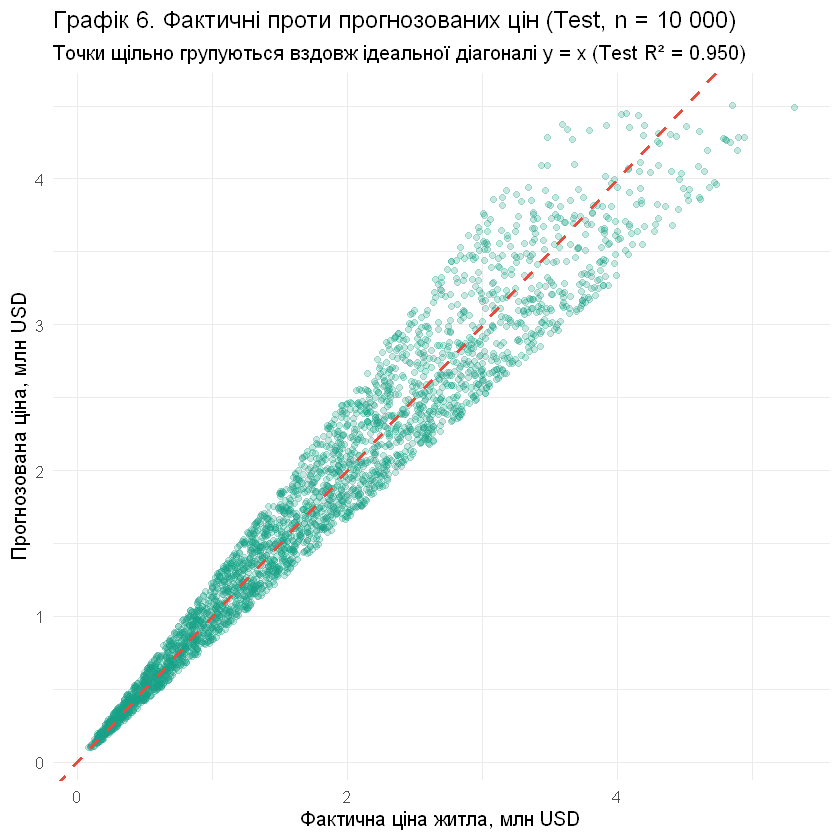

In [24]:
set.seed(42)
test_sample <- slice_sample(test_results, n = 3000)

ggplot(test_sample, aes(x = Price_USD / 1e6, y = pred_final / 1e6)) +
  geom_point(alpha = 0.25, color = "#16a085") +
  geom_abline(slope = 1, intercept = 0, color = "#e74c3c", linetype = "dashed", linewidth = 0.9) +
  labs(
    title = "Графік 6. Фактичні проти прогнозованих цін (Test, n = 10 000)",
    subtitle = "Точки щільно групуються вздовж ідеальної діагоналі y = x (Test R² = 0.950)",
    x = "Фактична ціна житла, млн USD",
    y = "Прогнозована ціна, млн USD"
  )

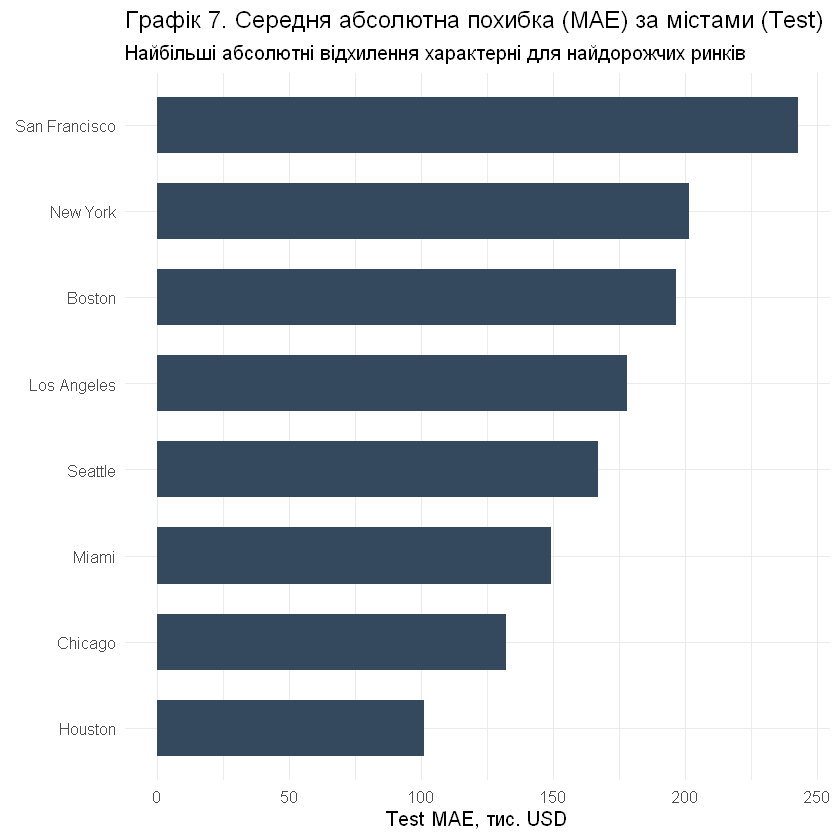

In [25]:
test_results |>
  group_by(Location) |>
  summarise(MAE_k = mean(abs_error) / 1000, .groups = "drop") |>
  ggplot(aes(x = reorder(Location, MAE_k), y = MAE_k)) +
  geom_col(fill = "#34495e", width = 0.65) +
  coord_flip() +
  labs(
    title = "Графік 7. Середня абсолютна похибка (MAE) за містами (Test)",
    subtitle = "Найбільші абсолютні відхилення характерні для найдорожчих ринків",
    x = NULL,
    y = "Test MAE, тис. USD"
  )

> **Проміжний висновок (аналіз якості прогнозу та структури помилок):**
> * На незалежній тестовій вибірці фінальна модель демонструє **$R^2 = 0.950$**, **$\text{Test MAE} = \$172\,856$** та **$\text{Test RMSE} = \$230\,755$** (проти $\text{MAE} = \$855\,510$ у константного прогнозу). Значення метрик на тесті майже збігаються з результатами крос-валідації, що підтверджує відсутність перенавчання.
> * **Де помилки найбільші:** Графік 6 та Графік 7 показують, що найбільші абсолютні помилки концентруються у **преміальному сегменті** — для великогабаритних об'єктів ($> 7\,500\text{ sq.ft}$) у найдорожчих мегаполісах (San Francisco: $\text{MAE} \approx \$235\text{ тис.}$, New York: $\approx \$210\text{ тис.}$), тоді як у Houston середня похибка становить лише $\approx \$105\text{ тис.}$ Це закономірний наслідок мультиплікативної структури ринкових відхилень, де випадкова варіація становить близько $\pm 20\%$ від базової вартості об'єкта.

## 4. Обговорення й висновки

1. **Відповідь на головне дослідницьке питання:**
   Лінійна регресійна модель із урахуванням взаємодії житлової площі та географічної локації пояснює **$95.0\%$ варіації цін** на нових спостереженнях ($R^2_{\text{test}} = 0.950$) і знижує середню абсолютну помилку прогнозування на **$79.8\%$** порівняно з константним орієнтиром ($\text{Test MAE} = \$172\,856$ проти $\$855\,510$). Ключовими детермінантами ціни є площа та місто, тоді як кількість спалень, ванних кімнат, наявність гаража, рік побудови, тип об'єкта та відстань до центру не дають статистично значущого внеску.

2. **Підсумки перевірки гіпотез з урахуванням невизначеності:**
   * **Гіпотеза $H_1$ (конфірматорна) підтверджена:** За фіксованого міста та інших характеристик житлова площа має сильний додатний лінійний зв'язок із ціною ($\hat{\beta}_{\text{Area}} = \$332.03/\text{sq.ft}$, $95\%$ робастний ДІ: $[\$330.89; \$333.16]$ у базовій моделі).
   * **Гіпотеза $H_2$ (розвідувальна) підтверджена:** Географічна локація статистично значуще модифікує вартість квадратного фута ($p < 0.001$ для всіх міст) — гранична ціна змінюється більш ніж удвічі: від $\approx \$200.07/\text{sq.ft}$ у Houston до $\approx \$451.54/\text{sq.ft}$ у San Francisco.

3. **Межі узагальнення та змішувальні чинники:**
   * Отримані оцінки описують **рівноважні статистичні асоціації** в межах вибірки восьми мегаполісів США і не можуть прямо переноситися на ринки інших країн, малі міста чи сільську місцевість.
   * Нульовий вплив відстані до центру, року побудови та типу житла свідчить про спрощену (напівсинтетичну) природу навчального датасету, де відсутні такі важливі змішувальні чинники реального ринку нерухомості, як стан ремонту, криміногенна ситуація в районі, якість шкільних округів, транспортна доступність та динаміка іпотечних ставок.

4. **Конкретне продовження дослідження:**
   * Для усунення гетероскедастичності залишків та звуження інтервалів прогнозу у верхньому ціновому сегменті доцільно протестувати **зважений метод найменших квадратів (WLS)** із вагами $w_i = 1/\text{Area\_sqft}_i^2$ або **логарифмічну специфікацію** $\log(\text{Price\_USD}) \sim \log(\text{Area\_sqft}) + \text{Location}$, яка вирівнює відносні похибки по всьому діапазону площ.